In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
pd.set_option("display.max_colwidth",None)

In [30]:
# breaking down this data a bit more
# fineVideo was a dataset i found on huggingface whose creators decided to scrape collective commons youtube videos
# the total datset was 43751 videos totaling up to 651 GB 
# each item in the dataset was a mp4 video + a nested json annotation 
# i only just pulled the jsons

# but i was interested in this dataset because it was an attempt 
# to create a dataset to teach VLMs how to "see" and understand video
# finevideo was interesting because it describes entire video structures not just short captions
# the videos was described fully by gemini 1.5 pro 
# then reformatted by GPT4o 
# its a cool dataset because there just aren't a lot of large dataset like this that was open-source

(43760, 5)

In [3]:
videos = pd.read_csv("data/videos.csv")
print(videos.shape)
videos.head()

(43751, 19)


,video,category,fine,duration,words,views,likes,comments,followers,channel,upload,resolution,n_scenes,n_qa,climax_frac,words_per_s,like_rate,year,mean_dynamism
0,d6b4OmUFt7I,Education,Engineering Projects,208,622,89462,555,0,34800,GovernmentofBC,20160511,640x360,5,5,0.509524,2.990385,0.006204,2016,0.580000
1,bswbQtOPk6E,Entertainment,Game Reviews,604,1751,38821,2251,468,103000,Ircha Gaming,20230406,640x360,15,5,0.756606,2.899007,0.057984,2023,0.513333
2,G_VTkkb34gw,Sports,Career Highlights,268,562,18366,0,0,11000,QueenslandPolice,20230921,640x360,6,5,0.701493,2.097015,0.000000,2023,0.666667
3,vd6hr_AtYtQ,Lifestyle,Recipe Videos,410,428,32265,297,40,33400,Valsala's Kitchen,20180911,626x360,5,5,0.882927,1.043902,0.009205,2018,0.680000
4,eLPe7xp0jRw,Lifestyle,Fashion Hauls,48,127,161401,3843,100,412000,Tanner Leatherstein,20240326,270x480,3,5,1.000000,2.645833,0.023810,2024,0.500000


In [33]:
videos.info()

<class 'pandas.DataFrame'>
RangeIndex: 43760 entries, 0 to 43759
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   video    43760 non-null  str  
 1   tenth    43760 non-null  int64
 2   n_lines  43760 non-null  int64
 3   words    43760 non-null  int64
 4   text     41136 non-null  str  
dtypes: int64(3), str(2)
memory usage: 1.7 MB


In [45]:
videos.columns

Index(['video', 'category', 'fine', 'duration', 'words', 'views', 'likes',
       'comments', 'followers', 'channel', 'upload', 'resolution', 'n_scenes',
       'n_qa', 'climax_frac', 'words_per_s', 'like_rate', 'year',
       'mean_dynamism'],
      dtype='str')

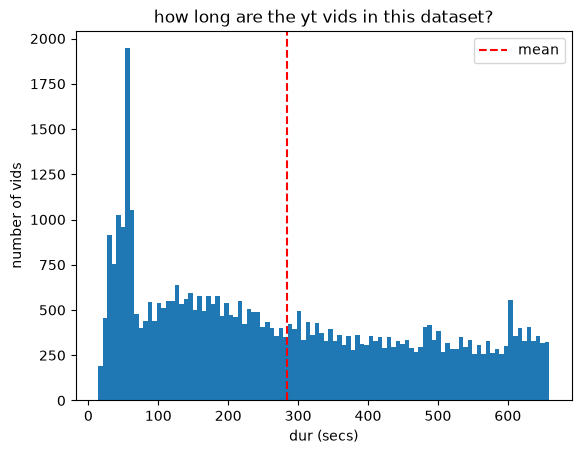

In [32]:
plt.hist(videos["duration"],bins=100)
plt.axvline(videos["duration"].mean(), color="red", linestyle="dashed", label="mean")
plt.xlabel("dur (secs)")
plt.ylabel("number of vids")
plt.title("how long are the yt vids in this dataset?")
plt.legend()
plt.show()

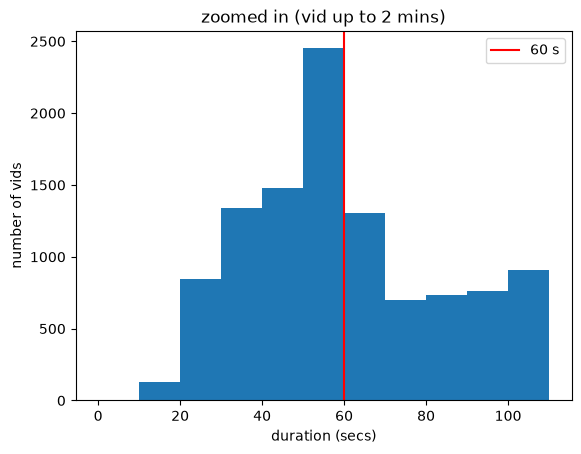

In [33]:
dur_zoom = videos[videos["duration"]<=120]
plt.hist(dur_zoom["duration"],bins=range(0,120,10))
plt.axvline(60, color="red", label="60 s")
plt.title("zoomed in (vid up to 2 mins)")
plt.xlabel("duration (secs)")
plt.ylabel("number of vids")
plt.legend()
plt.show()

In [53]:
# and just to follow along with some more of the Kat pokemon example
# simple stupid coor grid lol 
# who knew longer videos have more words in them 
# however longer videos don't nessessarily get more views either

grid_cols = ["duration","words","views"]
corr = videos[grid_cols].corr()
corr

,duration,words,views
duration,1.000000,0.871277,-0.032727
words,0.871277,1.000000,-0.039180
views,-0.032727,-0.039180,1.000000


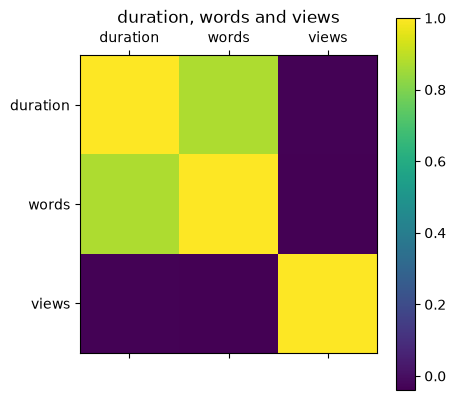

In [54]:
plt.matshow(corr)
plt.xticks(range(3),grid_cols)
plt.yticks(range(3),grid_cols)
plt.colorbar()
plt.title("duration, words and views")
plt.show()

In [39]:
# a condensed version of the transcript matching the vids of the original dataset above
# only 10% of the vids for easier processing

transcript = pd.read_csv("data/transcript_tenths_sample.csv")
transcript.info()

<class 'pandas.DataFrame'>
RangeIndex: 43760 entries, 0 to 43759
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   video    43760 non-null  str  
 1   tenth    43760 non-null  int64
 2   n_lines  43760 non-null  int64
 3   words    43760 non-null  int64
 4   text     41136 non-null  str  
dtypes: int64(3), str(2)
memory usage: 1.7 MB


In [46]:
# how many yt video end with one of these phrases?
# my transcripts table rn have 10 rows per vids


# idea is smth like this
# we want to mark every slice that says one of our output phrases
# keep only the last slice of that video to keep it light 
# take the mean of that last outro slice - this will give us the % of vids that have it at the end
# merge it back with the main csv based on category of vids 
# plot!

pattern = "subscribe|thanks for watching|thank you for watching"
transcript["outro"] = transcript["text"].str.contains(pattern)
transcript["outro"].sum()

np.int64(1087)

In [42]:
vid_end = transcript[transcript["tenth"]==9]
vid_end["outro"].mean()*100

np.float64(14.145338208409505)

In [43]:
vid_end = vid_end.merge(videos[["video","category"]], on="video")
vid_end.shape

(4376, 7)

In [44]:
by_cat = (vid_end.groupby("category")["outro"].mean()*100).sort_values()
by_cat

category
Science & Technology     6.529851
News & Politics          7.188161
Sports                   8.653846
Entertainment            9.041394
Education               14.497041
Art & Creativity        16.860465
Automotive              21.935484
Lifestyle               24.686192
Hobbies & Interests     27.272727
Name: outro, dtype: float64

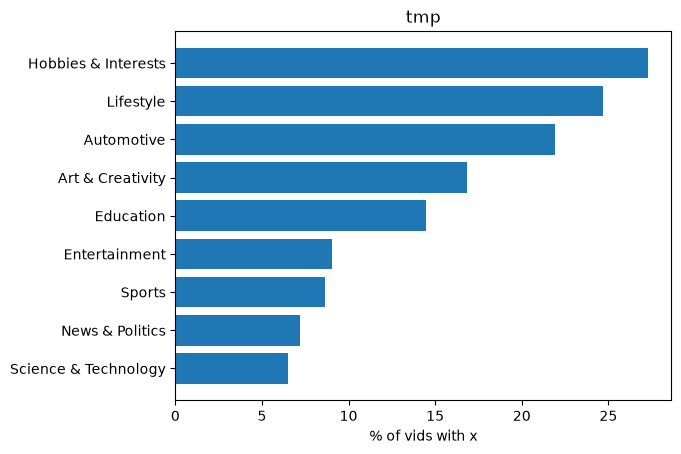

In [45]:
plt.barh(by_cat.index,by_cat.values)
plt.title('tmp')
plt.xlabel('% of vids with x')
plt.show()

In [ ]:
# i wasn't able to have enough time to finish this one BUT!
# wanted to move onto then doing a data-viz for what the did the models themselves
# think of these videos and what types of videos did they gravitate towards